# SPUS vs S&P500

### This notebook aims at systematically studying the behaviour of both markets

# Import

In [10]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats

from data import download_prices, compute_returns
from universe import get_universe, universe_diff, get_full_universe
from metrics import sharpe_ratio, annualised_return, max_drawdown, summary
from volatility import (
    rolling_vol, ewma_vol,
    fit_garch_universe, garch_conditional_vol,
    compare_universes
)
from signals import cross_section_zscore, momentum, short_term_reversal, volatility_signal

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120
print('Imports OK')

Imports OK


In [4]:
sp500_tickers = get_full_universe('sp500')
spus_tickers  = get_full_universe('spus')

all_tickers  = list(set(sp500_tickers + spus_tickers))
prices_all   = download_prices(all_tickers, start='2015-01-01')

sp500_cols   = [t for t in sp500_tickers if t in prices_all.columns]
spus_cols    = [t for t in spus_tickers  if t in prices_all.columns]

prices_sp500 = prices_all[sp500_cols]
prices_spus  = prices_all[spus_cols]
returns_sp500 = compute_returns(prices_all[sp500_cols])
returns_spus  = compute_returns(prices_all[spus_cols])

print(f'SP500: {returns_sp500.shape[1]} stocks | SPUS: {returns_spus.shape[1]} stocks')

Fetched 503 S&P 500 tickers from Wikipedia
Fetched 503 S&P 500 tickers from Wikipedia
SPUS: 422 stocks (excluded 81)
Loading from cache: prices_2015-01-01_today.csv
SP500: 470 stocks | SPUS: 392 stocks


In [5]:
# Define columns in SP500 not in SPUS
columns_not_in_both = set(prices_sp500.columns) ^ set(prices_spus.columns)

prices_diff = pd.concat(
    [prices_sp500.reindex(columns=columns_not_in_both),
     prices_spus.reindex(columns=columns_not_in_both)],
    axis=0
)

returns_diff = pd.concat(
    [returns_sp500.reindex(columns=columns_not_in_both),
     returns_spus.reindex(columns=columns_not_in_both)],
    axis=0
)

In [8]:
columns_not_in_both = np.array(list(columns_not_in_both))

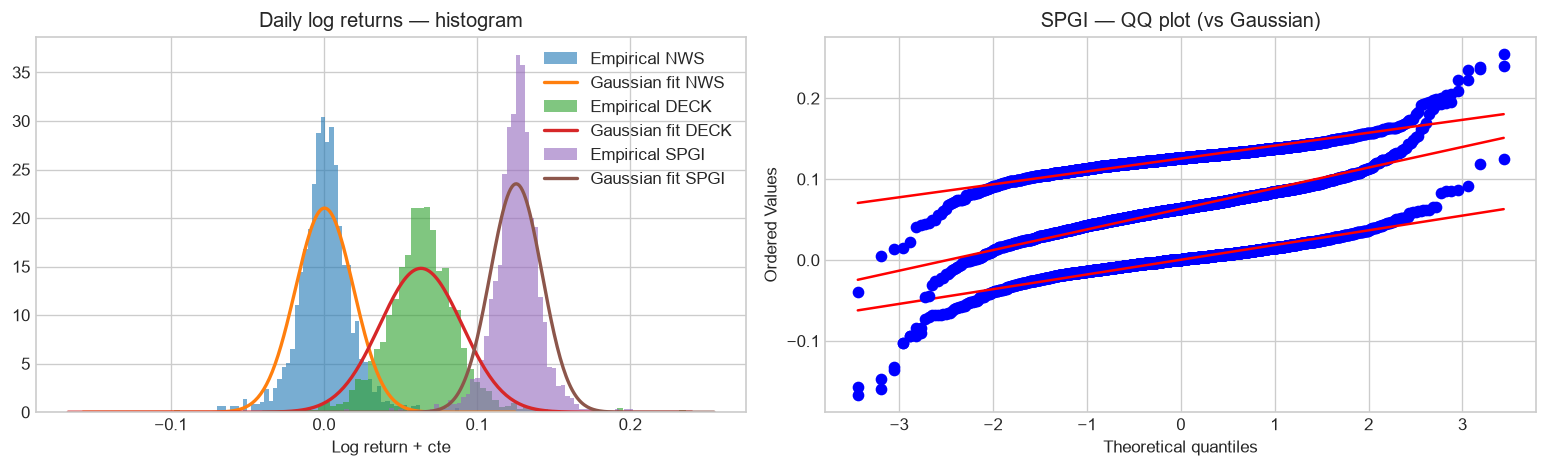

In [31]:
# Pick a representative stock
ticker_list = np.random.choice(list(prices_spus.columns), size=3, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i in range(len(ticker_list)):
    ticker = ticker_list[i]
    r = returns_spus[ticker].dropna() + i/16
    # Histogram vs Gaussian
    ax = axes[0]
    r.hist(bins=100, density=True, alpha=0.6, ax=ax, label=f'Empirical {ticker}')
    x = np.linspace(r.min(), r.max(), 300)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), lw=2, label=f'Gaussian fit {ticker}')
    
    
    
    # QQ plot
    ax = axes[1]
    stats.probplot(r, dist='norm', plot=ax)
axes[0].set_title(f'Daily log returns — histogram')
axes[1].set_title(f'{ticker} — QQ plot (vs Gaussian)')
axes[0].set_xlabel('Log return + cte'); axes[0].legend() 
plt.tight_layout()
plt.show()
    
    #print(f'Skewness : {r.skew():.3f}  (Gaussian = 0)')
    #print(f'Kurtosis : {r.kurtosis():.3f}  (Gaussian = 0, excess)')
    #print(f'Fat tails confirmed: kurtosis >> 0')

In [39]:
sharpe_sp500 = []
ann_return_sp500 = []
mdd_sp500 = []
for s in returns_sp500.columns:
    print(s)
    stats = summary(returns_sp500[s])
    sharpe_sp500.append(float(stats['Sharpe (gross)']))
    ann_return_sp500.append(float(stats['Annualised Return'][:-1]))
    mdd_sp500.append(float(stats['Max Drawdown'][:-1]))

MMM
  Annualised Return                            : -0.36%
  Sharpe (gross)                               : 0.12
  Max Drawdown                                 : -67.12%
AOS
  Annualised Return                            : -1.07%
  Sharpe (gross)                               : 0.10
  Max Drawdown                                 : -51.40%
ABT
  Annualised Return                            : 8.51%
  Sharpe (gross)                               : 0.46
  Max Drawdown                                 : -43.09%
ABBV
  Annualised Return                            : 17.43%
  Sharpe (gross)                               : 0.74
  Max Drawdown                                 : -49.64%
ACN
  Annualised Return                            : 4.08%
  Sharpe (gross)                               : 0.28
  Max Drawdown                                 : -74.31%
ADBE
  Annualised Return                            : -0.22%
  Sharpe (gross)                               : 0.18
  Max Drawdown                 

In [40]:
sharpe_spus = []
ann_return_spus = []
mdd_spus = []
for s in returns_spus.columns:
    print(s)
    stats = summary(returns_sp500[s])
    sharpe_spus.append(float(stats['Sharpe (gross)']))
    ann_return_spus.append(float(stats['Annualised Return'][:-1]))
    mdd_spus.append(float(stats['Max Drawdown'][:-1]))

MMM
  Annualised Return                            : -0.36%
  Sharpe (gross)                               : 0.12
  Max Drawdown                                 : -67.12%
AOS
  Annualised Return                            : -1.07%
  Sharpe (gross)                               : 0.10
  Max Drawdown                                 : -51.40%
ABT
  Annualised Return                            : 8.51%
  Sharpe (gross)                               : 0.46
  Max Drawdown                                 : -43.09%
ABBV
  Annualised Return                            : 17.43%
  Sharpe (gross)                               : 0.74
  Max Drawdown                                 : -49.64%
ACN
  Annualised Return                            : 4.08%
  Sharpe (gross)                               : 0.28
  Max Drawdown                                 : -74.31%
ADBE
  Annualised Return                            : -0.22%
  Sharpe (gross)                               : 0.18
  Max Drawdown                 

In [41]:
sharpe_diff = []
ann_return_diff = []
mdd_diff = []
for s in columns_not_in_both:
    print(s)
    stats = summary(returns_diff[s])
    sharpe_diff.append(float(stats['Sharpe (gross)']))
    ann_return_diff.append(float(stats['Annualised Return'][:-1]))
    mdd_diff.append(float(stats['Max Drawdown'][:-1]))

PM
  Annualised Return                            : 4.22%
  Sharpe (gross)                               : 0.45
  Max Drawdown                                 : -49.48%
KEY
  Annualised Return                            : -1.59%
  Sharpe (gross)                               : 0.13
  Max Drawdown                                 : -72.59%
EQIX
  Annualised Return                            : 3.66%
  Sharpe (gross)                               : 0.40
  Max Drawdown                                 : -45.04%
WRB
  Annualised Return                            : 6.72%
  Sharpe (gross)                               : 0.64
  Max Drawdown                                 : -48.35%
ERIE
  Annualised Return                            : 2.29%
  Sharpe (gross)                               : 0.30
  Max Drawdown                                 : -64.32%
WFC
  Annualised Return                            : 1.01%
  Sharpe (gross)                               : 0.23
  Max Drawdown                     

In [42]:
print('S&P500 mean +/- std')
print(f'Sharpe : {np.mean(sharpe_sp500):.2f} +/- {np.std(sharpe_sp500):.2f}')
print(f'Annualised Return : {np.mean(ann_return_sp500):.2f}% +/- {np.std(ann_return_sp500):.2f}%')
print(f'Max Drawdown : {np.mean(mdd_sp500):.2f}% +/- {np.std(mdd_sp500):.2f}%')
print('--------------------')
print('SPUS mean +/- std')
print(f'Sharpe : {np.mean(sharpe_spus):.2f} +/- {np.std(sharpe_spus):.2f}')
print(f'Annualised Return : {np.mean(ann_return_spus):.2f}% +/- {np.std(ann_return_spus):.2f}%')
print(f'Max Drawdown : {np.mean(mdd_spus):.2f}% +/- {np.std(mdd_spus):.2f}%')
print('--------------------')
print('Diff mean +/- std')
print(f'Sharpe : {np.mean(sharpe_diff):.2f} +/- {np.std(sharpe_diff):.2f}')
print(f'Annualised Return : {np.mean(ann_return_diff):.2f}% +/- {np.std(ann_return_diff):.2f}%')
print(f'Max Drawdown : {np.mean(mdd_diff):.2f}% +/- {np.std(mdd_diff):.2f}%')


S&P500 mean +/- std
Sharpe : 0.35 +/- 0.23
Annualised Return : 5.81% +/- 8.97%
Max Drawdown : -59.28% +/- 15.99%
--------------------
SPUS mean +/- std
Sharpe : 0.36 +/- 0.24
Annualised Return : 6.09% +/- 9.31%
Max Drawdown : -59.24% +/- 16.64%
--------------------
Diff mean +/- std
Sharpe : 0.31 +/- 0.20
Annualised Return : 2.12% +/- 3.38%
Max Drawdown : -59.49% +/- 12.20%


In [45]:
from scipy import stats as scipy_stats

t_stat, p_val = scipy_stats.ttest_ind(ann_return_spus, ann_return_sp500)
print(f"SPUS vs S&P500 p-value: {p_val:.4f}")
t_stat, p_val = scipy_stats.ttest_ind(ann_return_spus, ann_return_diff)
print(f"SPUS vs Diff p-value: {p_val:.4f}")
t_stat, p_val = scipy_stats.ttest_ind(ann_return_sp500, ann_return_diff)
print(f"SP500 vs Diff p-value: {p_val:.4f}")

SPUS vs S&P500 p-value: 0.6528
SPUS vs Diff p-value: 0.0002
SP500 vs Diff p-value: 0.0004


### Information coefficient (IC)
<u>Spearman correlation : </u> does the ordering of the signal match the ordering of the returns after 21 days? Measure correlations and assign a score (IC). If IC = 1, perfect ordering. If IC = 0, disordered completely. Generally, a mean IC of 0.01-0.04 is a good indication that the signal is exploitable because markets are not that predictable.  
<u> Pearson correlation : </u> is there a linear relationship between these numbers (stocks with higher singal score returned proportionally more)? 


In [54]:
from scipy import stats as scipy_stats
def information_coefficient(signal: pd.DataFrame,
                            returns: pd.DataFrame,
                            horizon: int = 21,
                            method: str = 'spearman') -> pd.Series:
    """
    method: 'spearman' (rank-based, robust) or 'pearson' (value-based, linear)
    """
    forward_ret = returns.rolling(horizon).sum().shift(-horizon)
    ics = []

    for date in signal.index.intersection(forward_ret.index):
        s = signal.loc[date].dropna()
        f = forward_ret.loc[date].dropna()
        common = s.index.intersection(f.index)
        if len(common) < 20:
            continue

        if method == 'spearman':
            ic, _ = scipy_stats.spearmanr(s[common], f[common])
        else:
            ic, _ = scipy_stats.pearsonr(s[common], f[common])

        ics.append({'date': date, 'IC': ic})

    return pd.DataFrame(ics).set_index('date')['IC'].dropna()

In [77]:
def ic_summary(ic: pd.Series, label: str = "") -> dict:
    """
    Print and return IC summary statistics.
    ICIR = IC / std(IC) — the signal's own Sharpe ratio.
    A signal with ICIR > 0.5 is considered tradeable.
    """
    mean_ic = ic.mean()
    std_ic  = ic.std()
    icir    = mean_ic / std_ic if std_ic > 0 else 0
    pct_pos = (ic > 0).mean() * 100
    t_stat  = mean_ic / (std_ic / np.sqrt(len(ic)))
    p_val   = 2 * (1 - scipy_stats.t.cdf(abs(t_stat), df=len(ic)-1))

    tag = f"[{label}] " if label else ""
    print(f"{tag}Mean IC : {mean_ic:.6f}")
    print(f"{tag}Std IC  : {std_ic:.6f}")
    print(f"{tag}ICIR    : {icir:.6f}")
    print(f"{tag}% positive: {pct_pos:.1f}%")
    print(f"{tag}t-stat  : {t_stat:.2f}  p-value: {p_val:.6f}")

    return dict(mean_ic=mean_ic, std_ic=std_ic, icir=icir,
                pct_pos=pct_pos, t_stat=t_stat, p_val=p_val)


In [78]:
mom_sp500 = momentum(returns_sp500)
mom_spus  = momentum(returns_spus)

vol_sp500 = volatility_signal(returns_sp500)
vol_spus  = volatility_signal(returns_spus)

rev_sp500 = short_term_reversal(returns_sp500)
rev_spus  = short_term_reversal(returns_spus)

## Spearman

In [87]:
ic_mom_sp500 = information_coefficient(mom_sp500, returns_sp500, method='spearman')
ic_mom_spus  = information_coefficient(mom_spus,  returns_spus, method='spearman')

ic_vol_sp500 = information_coefficient(vol_sp500, returns_sp500, method='spearman')
ic_vol_spus  = information_coefficient(vol_spus,  returns_spus, method='spearman')

ic_rev_sp500 = information_coefficient(rev_sp500, returns_sp500, method='spearman')
ic_rev_spus  = information_coefficient(rev_spus,  returns_spus, method='spearman')

In [80]:
signals = {
    'Momentum':  (ic_mom_sp500, ic_mom_spus),
    'Volatility': (ic_vol_sp500, ic_vol_spus),
    'Reversal':  (ic_rev_sp500, ic_rev_spus),
}

print("\n" + "="*60)
for sig_name, (ic_s, ic_u) in signals.items():
    print(f"\n{sig_name}")
    print("-"*40)
    ic_summary(ic_s, label="SP500")
    print()
    ic_summary(ic_u, label="SPUS")
print("="*60)



Momentum
----------------------------------------
[SP500] Mean IC : 0.004176
[SP500] Std IC  : 0.210256
[SP500] ICIR    : 0.019861
[SP500] % positive: 55.2%
[SP500] t-stat  : 0.91  p-value: 0.364352

[SPUS] Mean IC : 0.004764
[SPUS] Std IC  : 0.204404
[SPUS] ICIR    : 0.023305
[SPUS] % positive: 54.3%
[SPUS] t-stat  : 1.06  p-value: 0.287153

Volatility
----------------------------------------
[SP500] Mean IC : -0.034412
[SP500] Std IC  : 0.217603
[SP500] ICIR    : -0.158140
[SP500] % positive: 44.9%
[SP500] t-stat  : -7.65  p-value: 0.000000

[SPUS] Mean IC : -0.034416
[SPUS] Std IC  : 0.215358
[SPUS] ICIR    : -0.159810
[SPUS] % positive: 46.1%
[SPUS] t-stat  : -7.73  p-value: 0.000000

Reversal
----------------------------------------
[SP500] Mean IC : 0.012374
[SP500] Std IC  : 0.168809
[SP500] ICIR    : 0.073302
[SP500] % positive: 53.3%
[SP500] t-stat  : 3.56  p-value: 0.000382

[SPUS] Mean IC : 0.011111
[SPUS] Std IC  : 0.164593
[SPUS] ICIR    : 0.067507
[SPUS] % positive: 52.

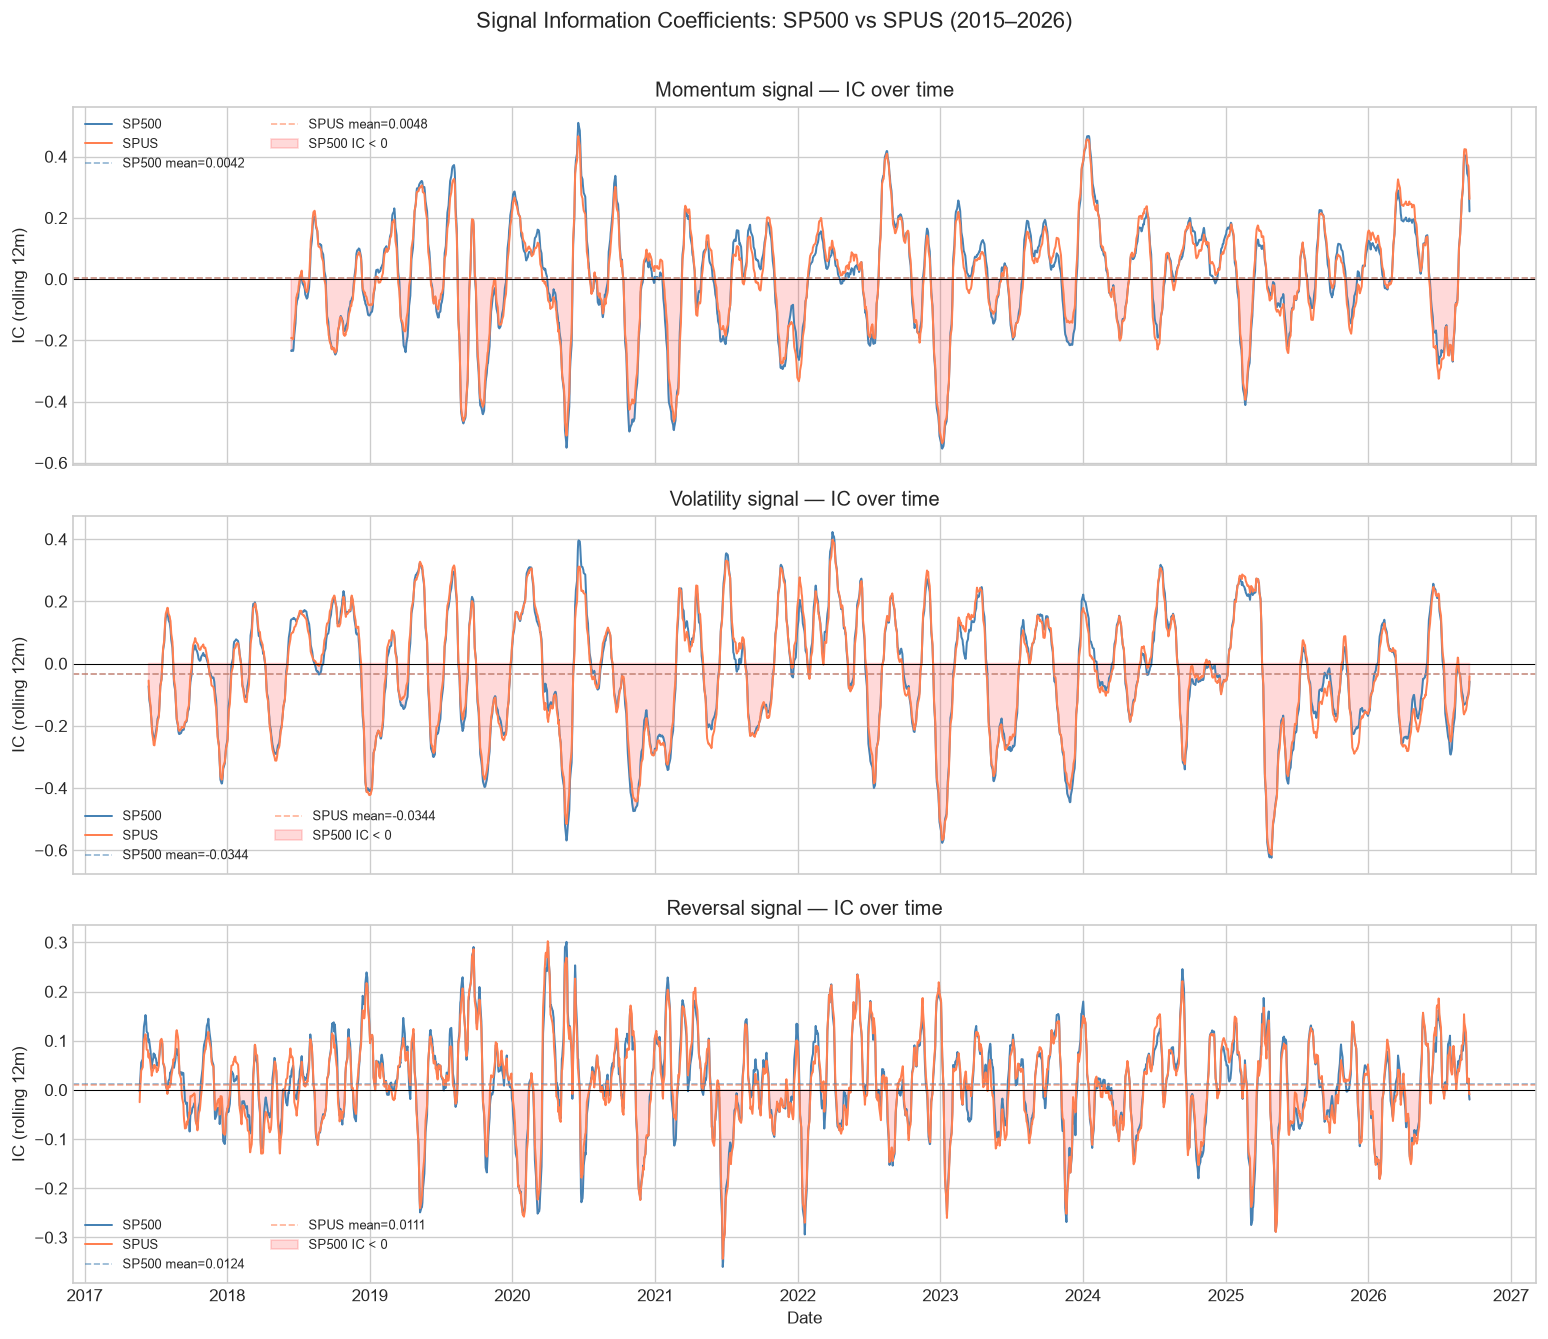

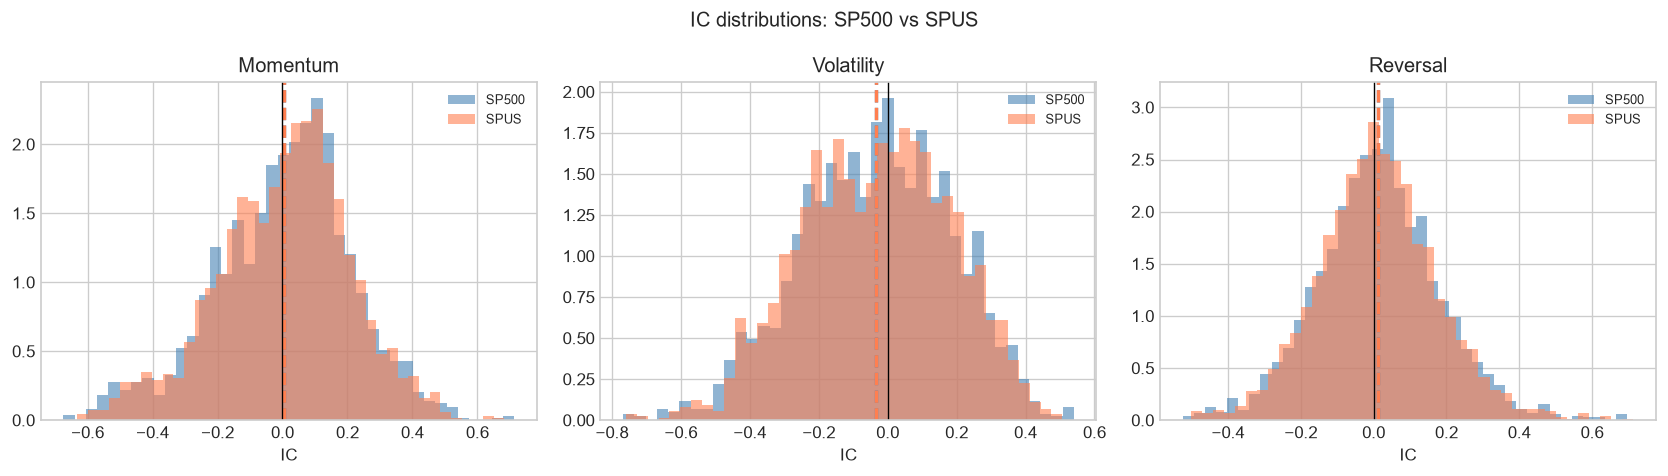

In [81]:

# ── Plot: rolling IC over time ────────────────────────────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
window = 12  # 12-month rolling mean

for ax, sig_name, (ic_s, ic_u) in zip(axes, signals.keys(), signals.values()):
    # Align series
    ic_s_roll = ic_s.rolling(window).mean()
    ic_u_roll = ic_u.rolling(window).mean()

    ax.plot(ic_s_roll, color='steelblue', lw=1.2, label='SP500')
    ax.plot(ic_u_roll, color='coral',     lw=1.2, label='SPUS')
    ax.axhline(0,              color='black', lw=0.6)
    ax.axhline(ic_s.mean(),   color='steelblue', ls='--', lw=1, alpha=0.6,
               label=f'SP500 mean={ic_s.mean():.4f}')
    ax.axhline(ic_u.mean(),   color='coral',     ls='--', lw=1, alpha=0.6,
               label=f'SPUS mean={ic_u.mean():.4f}')

    # Shade periods where IC is negative (signal not working)
    combined = ic_s_roll.reindex(ic_u_roll.index.union(ic_s_roll.index))
    ax.fill_between(ic_s_roll.index, ic_s_roll, 0,
                    where=ic_s_roll < 0,
                    alpha=0.15, color='red', label='SP500 IC < 0')

    ax.set_ylabel('IC (rolling 12m)')
    ax.set_title(f'{sig_name} signal — IC over time')
    ax.legend(fontsize=8, ncol=2)
    #ax.set_ylim(-0.15, 0.15)

axes[-1].set_xlabel('Date')
plt.suptitle('Signal Information Coefficients: SP500 vs SPUS (2015–2026)',
             y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


# ── IC distribution comparison ────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, sig_name, (ic_s, ic_u) in zip(axes, signals.keys(), signals.values()):
    ax.hist(ic_s, bins=40, alpha=0.6, color='steelblue',
            density=True, label='SP500')
    ax.hist(ic_u, bins=40, alpha=0.6, color='coral',
            density=True, label='SPUS')
    ax.axvline(ic_s.mean(), color='steelblue', ls='--', lw=2)
    ax.axvline(ic_u.mean(), color='coral',     ls='--', lw=2)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{sig_name}')
    ax.set_xlabel('IC')
    ax.legend(fontsize=8)

plt.suptitle('IC distributions: SP500 vs SPUS', fontsize=12)
plt.tight_layout()
plt.show()

In [88]:
for sig_name, (ic_s, ic_u) in zip(
    ['Momentum', 'Volatility', 'Reversal'],
    [(ic_mom_sp500, ic_mom_spus),
     (ic_vol_sp500, ic_vol_spus),
     (ic_rev_sp500, ic_rev_spus)]
):
    common = ic_s.index.intersection(ic_u.index)
    t, p = scipy_stats.ttest_ind(ic_s[common], ic_u[common])
    print(f"{sig_name}: SP500 vs SPUS IC p-value = {p:.4f}")

Momentum: SP500 vs SPUS IC p-value = 0.9270
Volatility: SP500 vs SPUS IC p-value = 0.9994
Reversal: SP500 vs SPUS IC p-value = 0.7949


## Pearson

In [82]:
ic_mom_sp500 = information_coefficient(mom_sp500, returns_sp500, method='pearson')
ic_mom_spus  = information_coefficient(mom_spus,  returns_spus, method='pearson')

ic_vol_sp500 = information_coefficient(vol_sp500, returns_sp500, method='pearson')
ic_vol_spus  = information_coefficient(vol_spus,  returns_spus, method='pearson')

ic_rev_sp500 = information_coefficient(rev_sp500, returns_sp500, method='pearson')
ic_rev_spus  = information_coefficient(rev_spus,  returns_spus, method='pearson')

In [83]:
signals = {
    'Momentum':  (ic_mom_sp500, ic_mom_spus),
    'Volatility': (ic_vol_sp500, ic_vol_spus),
    'Reversal':  (ic_rev_sp500, ic_rev_spus),
}

print("\n" + "="*60)
for sig_name, (ic_s, ic_u) in signals.items():
    print(f"\n{sig_name}")
    print("-"*40)
    ic_summary(ic_s, label="SP500")
    print()
    ic_summary(ic_u, label="SPUS")
print("="*60)



Momentum
----------------------------------------
[SP500] Mean IC : 0.015434
[SP500] Std IC  : 0.224515
[SP500] ICIR    : 0.068746
[SP500] % positive: 57.2%
[SP500] t-stat  : 3.14  p-value: 0.001710

[SPUS] Mean IC : 0.017931
[SPUS] Std IC  : 0.224445
[SPUS] ICIR    : 0.079891
[SPUS] % positive: 57.1%
[SPUS] t-stat  : 3.65  p-value: 0.000269

Volatility
----------------------------------------
[SP500] Mean IC : -0.040268
[SP500] Std IC  : 0.225059
[SP500] ICIR    : -0.178923
[SP500] % positive: 44.0%
[SP500] t-stat  : -8.65  p-value: 0.000000

[SPUS] Mean IC : -0.040952
[SPUS] Std IC  : 0.227438
[SPUS] ICIR    : -0.180056
[SPUS] % positive: 44.2%
[SPUS] t-stat  : -8.71  p-value: 0.000000

Reversal
----------------------------------------
[SP500] Mean IC : 0.007914
[SP500] Std IC  : 0.169006
[SP500] ICIR    : 0.046826
[SP500] % positive: 50.8%
[SP500] t-stat  : 2.27  p-value: 0.023154

[SPUS] Mean IC : 0.005446
[SPUS] Std IC  : 0.169405
[SPUS] ICIR    : 0.032148
[SPUS] % positive: 49.

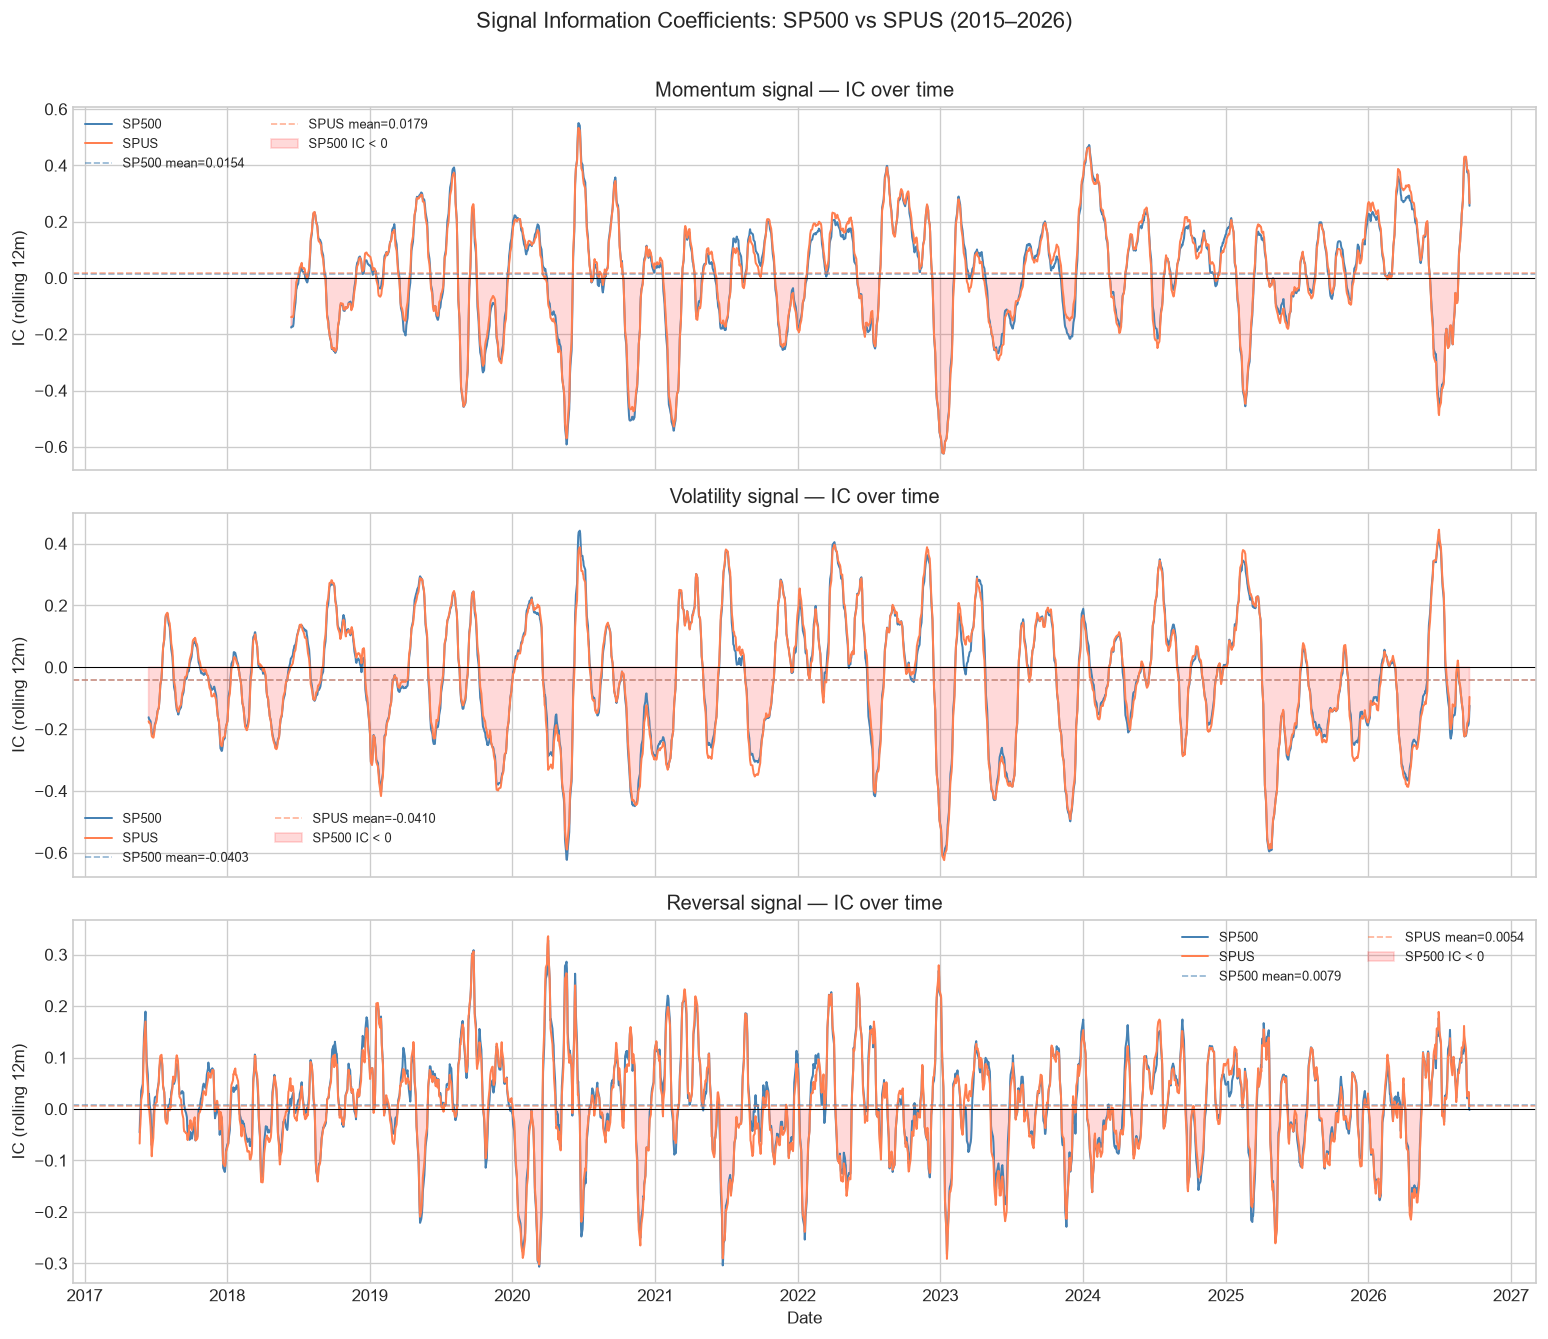

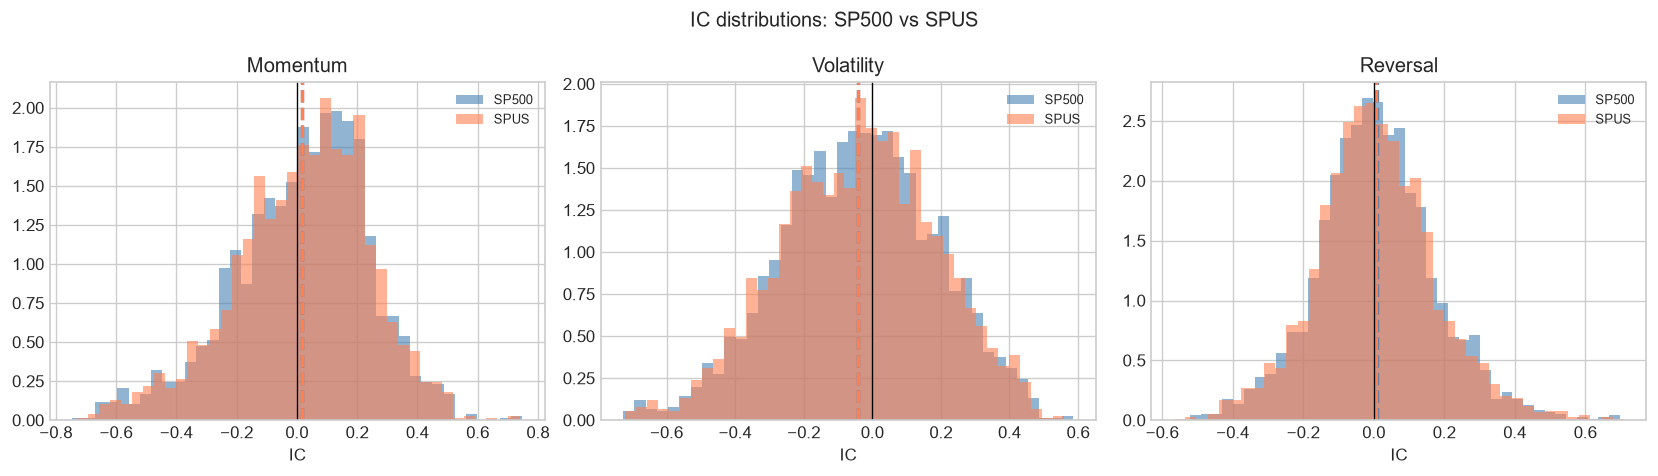

In [84]:

# ── Plot: rolling IC over time ────────────────────────────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
window = 12  # 12-month rolling mean

for ax, sig_name, (ic_s, ic_u) in zip(axes, signals.keys(), signals.values()):
    # Align series
    ic_s_roll = ic_s.rolling(window).mean()
    ic_u_roll = ic_u.rolling(window).mean()

    ax.plot(ic_s_roll, color='steelblue', lw=1.2, label='SP500')
    ax.plot(ic_u_roll, color='coral',     lw=1.2, label='SPUS')
    ax.axhline(0,              color='black', lw=0.6)
    ax.axhline(ic_s.mean(),   color='steelblue', ls='--', lw=1, alpha=0.6,
               label=f'SP500 mean={ic_s.mean():.4f}')
    ax.axhline(ic_u.mean(),   color='coral',     ls='--', lw=1, alpha=0.6,
               label=f'SPUS mean={ic_u.mean():.4f}')

    # Shade periods where IC is negative (signal not working)
    combined = ic_s_roll.reindex(ic_u_roll.index.union(ic_s_roll.index))
    ax.fill_between(ic_s_roll.index, ic_s_roll, 0,
                    where=ic_s_roll < 0,
                    alpha=0.15, color='red', label='SP500 IC < 0')

    ax.set_ylabel('IC (rolling 12m)')
    ax.set_title(f'{sig_name} signal — IC over time')
    ax.legend(fontsize=8, ncol=2)
    #ax.set_ylim(-0.15, 0.15)

axes[-1].set_xlabel('Date')
plt.suptitle('Signal Information Coefficients: SP500 vs SPUS (2015–2026)',
             y=1.01, fontsize=13)
plt.tight_layout()
plt.show()


# ── IC distribution comparison ────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, sig_name, (ic_s, ic_u) in zip(axes, signals.keys(), signals.values()):
    ax.hist(ic_s, bins=40, alpha=0.6, color='steelblue',
            density=True, label='SP500')
    ax.hist(ic_u, bins=40, alpha=0.6, color='coral',
            density=True, label='SPUS')
    ax.axvline(ic_s.mean(), color='steelblue', ls='--', lw=2)
    ax.axvline(ic_u.mean(), color='coral',     ls='--', lw=2)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(f'{sig_name}')
    ax.set_xlabel('IC')
    ax.legend(fontsize=8)

plt.suptitle('IC distributions: SP500 vs SPUS', fontsize=12)
plt.tight_layout()
plt.show()

In [86]:
for sig_name, (ic_s, ic_u) in zip(
    ['Momentum', 'Volatility', 'Reversal'],
    [(ic_mom_sp500, ic_mom_spus),
     (ic_vol_sp500, ic_vol_spus),
     (ic_rev_sp500, ic_rev_spus)]
):
    common = ic_s.index.intersection(ic_u.index)
    t, p = scipy_stats.ttest_ind(ic_s[common], ic_u[common])
    print(f"{sig_name}: SP500 vs SPUS IC p-value = {p:.4f}")

Momentum: SP500 vs SPUS IC p-value = 0.7194
Volatility: SP500 vs SPUS IC p-value = 0.9177
Reversal: SP500 vs SPUS IC p-value = 0.6168


## Conclusion
We compare three equity universes over the 2015–2026 period: the full S&P 500 (470 stocks), a Sharia-screened subset (SPUS, 392 stocks after Stage 1 business activity exclusions), and the excluded companies (Diff, 78 stocks).  

### Return and risk metrics

Mean annualised returns are $5.81\% \pm 8.97\%$ for SP500, $6.09\% \pm 9.31\%$ for SPUS, and $2.12\% \pm 3.38\%$ for the excluded companies. While SPUS shows a marginally higher mean return than S&P500, this difference is not statistically significant ($p=0.65$). Both S&P500 and SPUS significantly outperform the excluded universe ($p=0.0002$ and $p=0.0004$ respectively), whose lower returns reflect the underperformance of conventional stocks over this period. Generally, these sectors saw a limited growth relative to the tech-heavy composition of the Sharia-screened universe.   
<br>
Mean Sharpe ratios are similar across all three groups (SP500: $0.35 \pm 0.23$, SPUS: $0.36 \pm 0.24$, Diff: $0.31 \pm 0.20$), with all values within one standard deviation of each other. Maximum drawdown is nearly identical across universes (approximately $−59\%$), indicating that Sharia screening provides no additional protection against statistically unlikely events.

### Signal analysis

We evaluate three systematic signals: momentum, short-term reversal, and volatility. We use both Spearman rank correlation and Pearson correlation between signal scores and 21-day forward returns.
<br>
Momentum shows no significant rank-predictive power in either universe under Spearman ($p=0.36$ for SP500, $p=0.29$ for SPUS), but exhibits significant magnitude predictability under Pearson ($p=0.002$ and $p=0.0003$) (Difficulty in predicting the order order of returns, but good at determining the magnitude of returns). This divergence indicates a non-linear relationship between momentum and returns, likely due to extreme momentum stocks outperform meaningfully, while the bulk of the ranking carries little signal. 
<br>
The volatility signal produces a significantly negative IC in both universes under both methods (Spearman IC $\approx −0.034$, $p<0.001$; Pearson IC $\approx −0.040$, $p<0.001$), meaning high-volatility stocks outperform low-volatility stocks at the 21-day horizon. This is a horizon effect rather than a contradiction of the low-volatility anomaly: at short horizons in trending markets, high-volatility stocks generate larger absolute moves. S&P500 and SPUS produce virtually identical volatility IC values, with a comparison p-value of 0.999.
<br>
Short-term reversal is the most robust signal, exhibiting significant rank-predictive power in both universes under Spearman (SP500: IC=0.012, $p=0.0004$; SPUS: IC=0.011, $p=0.001$). Under Pearson, reversal magnitude is significant for S&P500 ($p=0.023$) but not for SPUS ($p=0.12$), suggesting that the excluded financial stocks contribute disproportionately to the magnitude predictability of the reversal signal in the unconstrained universe.

<br>
Across all three signals and both correlation methods, direct comparison of IC series between S&P500 and SPUS yields p-values above $0.6$ in all cases (Spearman: momentum $p=0.93$, volatility $p=0.999$, reversal $p=0.79$; Pearson: momentum $p=0.72$, volatility $p=0.92$, reversal $p=0.62$). The signal predictive structure is statistically the same between the two universes. Sharia screening removes a specific underperforming segment of the market while leaving the return-generating structure of the remaining universe entirely intact. A systematic strategy calibrated on the full S&P 500 would transfer to the Sharia-screened universe without recalibration.